In [9]:
import pandas as pd
import numpy as np
import torch

from matplotlib import pyplot
from mpl_toolkits.mplot3d import Axes3D

In [46]:
device = torch.device("cpu")

path = "dataset/diabetes.csv"
df = pd.read_csv(path)

Y_raw = df['Income'].values
#X_raw = df.drop(columns=['Diabetes_012', 'Income']).values
#X_raw = df.drop(columns=['Income']).values
X_raw = df.iloc[:, :21].values

#X = torch.from_numpy(X_raw).float()
#y = torch.from_numpy(Y_raw).float().unsqueeze(1) #Duda porque solamente aqui se usa unsqueeze

m = X_raw.shape[0]

#torch.manual_seed(42)
#indices = torch.randperm(m)
#X = X[indices]
#y = y[indices]

train_size = int(0.8 * m)

X_t, X_ts = X_raw[:train_size], X_raw[train_size:]
y_t, y_ts = Y_raw[:train_size], Y_raw[train_size:]

X_train = torch.from_numpy(X_t).float()
y_train = torch.from_numpy(y_t).float().unsqueeze(1)

print(f"Total de muestras (m): {m}")
print(f"X_t shape: {X_train.shape} | Dispositivo: {X_train.device}")
print(f"X_ts shape:  {X_ts.shape}  | Dispositivo: {X_ts.device}")

print(f"Y_train shape: {y_train.shape} | Dispositivo: {y_train.device}")
print(f"Y_test shape:  {y_ts.shape}  | Dispositivo: {y_ts.device}")

Total de muestras (m): 253680
X_t shape: torch.Size([202944, 21]) | Dispositivo: cpu
X_ts shape:  (50736, 21)  | Dispositivo: cpu
Y_train shape: torch.Size([202944, 1]) | Dispositivo: cpu
Y_test shape:  (50736,)  | Dispositivo: cpu


In [47]:
print(X_train)
print(y_train)

tensor([[0., 1., 1.,  ..., 0., 9., 4.],
        [0., 0., 0.,  ..., 0., 7., 6.],
        [0., 1., 1.,  ..., 0., 9., 4.],
        ...,
        [0., 0., 0.,  ..., 0., 3., 5.],
        [0., 0., 0.,  ..., 0., 3., 5.],
        [0., 0., 0.,  ..., 0., 3., 6.]])
tensor([[3.],
        [1.],
        [8.],
        ...,
        [6.],
        [8.],
        [6.]])


In [49]:
def featureNormalize(X,y):
    
    mu = X.mean(dim=0)
    sigma = X.std(dim=0)

    mu_y = y.mean(dim=0)
    sigma_y = y.std(dim=0)

    X_norm = (X - mu) / sigma
    y_norm = (y - mu_y) / sigma_y

    return X_norm, y_norm, mu, mu_y, sigma, sigma_y


X_train_norm, y_train_norm, mu, mu_y, sigma, sigma_y = featureNormalize(X_train, y_train)

print(X_train_norm)
print(y_train_norm)

tensor([[-0.4246,  1.1512,  1.1639,  ..., -0.8859,  0.3055, -1.0802],
        [-0.4246, -0.8687, -0.8592,  ..., -0.8859, -0.3513,  0.9630],
        [-0.4246,  1.1512,  1.1639,  ..., -0.8859,  0.3055, -1.0802],
        ...,
        [-0.4246, -0.8687, -0.8592,  ..., -0.8859, -1.6651, -0.0586],
        [-0.4246, -0.8687, -0.8592,  ..., -0.8859, -1.6651, -0.0586],
        [-0.4246, -0.8687, -0.8592,  ..., -0.8859, -1.6651,  0.9630]])
tensor([[-1.5021],
        [-2.4772],
        [ 0.9358],
        ...,
        [-0.0394],
        [ 0.9358],
        [-0.0394]])


In [83]:
D_in, H1, D_out = 21, 10, 1

model = torch.nn.Sequential(
    torch.nn.Linear(D_in, H1),
    torch.nn.ReLU(),
    #torch.nn.Linear(H1, H2),
    #torch.nn.ReLU(),
    #torch.nn.Linear(H2, H3),
    #torch.nn.ReLU(),
    torch.nn.Linear(H1, D_out)
).to(device)

criterion = torch.nn.MSELoss()

optimizer = torch.optim.SGD(model.parameters(), lr=0.15)
#optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 300
log_each = 20
l = []

model.train()

for e in range(1, epochs + 1):

    # forward
    y_pred = model(X_train_norm)

    # loss
    loss = criterion(y_pred, y_train_norm)
    l.append(loss.item())

    # ponemos a cero los gradientes
    optimizer.zero_grad()

    # Backprop (calculamos todos los gradientes automáticamente)
    loss.backward()

    # update de los pesos
    optimizer.step()

    if not e % log_each:
        print(f"Epoch {e}/{epochs} Loss {np.mean(l):.5f}")

Epoch 20/300 Loss 0.76407
Epoch 40/300 Loss 0.71787
Epoch 60/300 Loss 0.69961
Epoch 80/300 Loss 0.68952
Epoch 100/300 Loss 0.68294
Epoch 120/300 Loss 0.67818
Epoch 140/300 Loss 0.67450
Epoch 160/300 Loss 0.67149
Epoch 180/300 Loss 0.66894
Epoch 200/300 Loss 0.66673
Epoch 220/300 Loss 0.66475
Epoch 240/300 Loss 0.66297
Epoch 260/300 Loss 0.66136
Epoch 280/300 Loss 0.65988
Epoch 300/300 Loss 0.65853


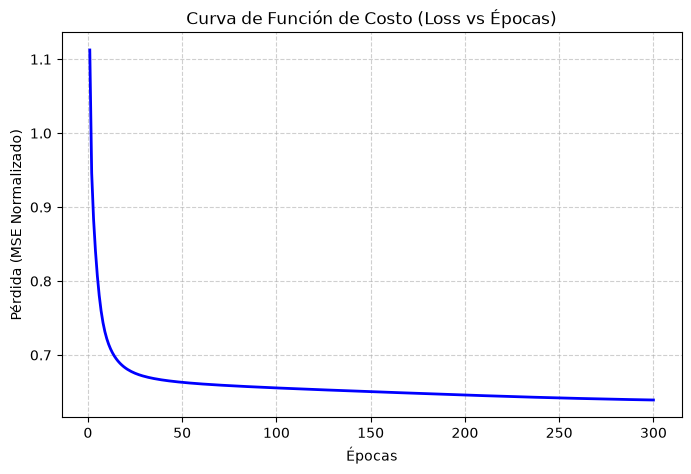

In [84]:
pyplot.figure(figsize=(8, 5))

pyplot.plot(range(1, epochs + 1), l, color='blue', linewidth=2)

pyplot.title('Curva de Función de Costo (Loss vs Épocas)')
pyplot.xlabel('Épocas')
pyplot.ylabel('Pérdida (MSE Normalizado)')
pyplot.grid(True, linestyle='--', alpha=0.6)

pyplot.show()

In [85]:
model.eval()

X_test = torch.from_numpy(X_ts).float()
y_test = torch.from_numpy(y_ts).float().unsqueeze(1)

X_test_norm = (X_test - mu) / sigma
y_test_norm = (y_test - mu_y) / sigma_y

with torch.no_grad():

    y_pred_test = model(X_test_norm)
    
    y_true_mean = torch.mean(y_test_norm)
    
    ss_res = torch.sum((y_test_norm - y_pred_test) ** 2)
    
    ss_tot = torch.sum((y_test_norm - y_true_mean) ** 2)
    
    r2_score = 1 - (ss_res / ss_tot)
    
    porcentaje_acierto = r2_score.item() * 100

print(f"\nPorcentaje de aprendizaje/ajuste: {porcentaje_acierto:.2f}%")


Porcentaje de aprendizaje/ajuste: 35.41%
